# Práctica 002: SVR para predecir ventas diarias

La portada (sección 0) la completa R4. Este archivo tiene por ahora las secciones 1 a 3 (R1, Datos y EDA); R2, R3 y R4 agregan el resto de las secciones del plan en sus ramas.

## 1. Configuración

Imports, rutas, semilla (`SEED = 42`, decisión cerrada del plan) y versiones de las librerías, para que cualquiera pueda reproducir los resultados. `guardar()` deja las figuras en `resultados/figuras/`.

In [1]:
import platform
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display

SEED = 42
np.random.seed(SEED)

RUTA_DATOS = Path("datos/ventas_features.csv")
RUTA_FIGURAS = Path("resultados/figuras")
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

display(pd.Series({"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                   "scikit-learn": sklearn.__version__, "seaborn": sns.__version__, "semilla": SEED}, name="versión"))


def guardar(fig, nombre):
    fig.savefig(RUTA_FIGURAS / nombre, dpi=150, bbox_inches="tight")

python          3.13.18
pandas            3.0.5
numpy             2.5.3
scikit-learn      1.9.1
seaborn          0.13.2
semilla              42
Name: versión, dtype: object

## 2. Datos y EDA mínimo

Usamos `ventas_features.csv` (práctica 001): ventas diarias de 10 productos durante 60 días, con calendario, rezagos de ventas, stock y caducidad. El target `cantidad_vendida` es continuo (unidades por día), por eso el modelo es una regresión (SVR). El EDA usa el dataset completo; el modelado usa solo las filas sin nulos (sección 3.2).

### 2.1 Carga y validación

Cargamos el CSV con la fecha como fecha real y comprobamos con `assert` que tiene la forma esperada, sin duplicados y con rangos coherentes.

In [2]:
df_crudo = pd.read_csv(RUTA_DATOS, parse_dates=["fecha_venta"])
df_crudo = df_crudo.sort_values(["fecha_venta", "product_id"]).reset_index(drop=True)
df = df_crudo.copy()  # EDA sobre el dataset completo; en 3.2 df pasa a ser el dataset limpio

assert df.shape == (600, 22) and df["product_id"].nunique() == 10
assert (df.groupby("product_id")["fecha_venta"].nunique() == 60).all()
assert not df.duplicated(["product_id", "fecha_venta"]).any()
assert df["dia_semana"].between(0, 6).all() and (df["cantidad_vendida"] > 0).all()
assert df[["es_fin_de_semana", "es_feriado"]].isin([0, 1]).all().all()

resumen = df.agg(["min", "max"]).T
resumen.insert(0, "tipo", df.dtypes.astype(str))
resumen.insert(1, "nulos", df.isna().sum())
resumen.insert(2, "distintos", df.nunique())
resumen

,tipo,nulos,distintos,min,max
product_id,str,0,10,P0001,P0010
nombre,str,0,10,Aceite vegetal,Papel higiénico
categoria,str,0,6,Alimentos,Snacks
unidad,str,0,5,docena,unidad
fecha_venta,datetime64[us],0,60,2022-01-01 00:00:00,2022-03-01 00:00:00
anio,int64,0,1,2022,2022
mes,int64,0,3,1,3
dia_del_mes,int64,0,31,1,31
dia_semana,int64,0,7,0,6
nombre_dia,str,0,7,Domingo,Viernes


### 2.2 Valores nulos

El dataset original (`sales_history.csv`) no tiene nulos. Los de `ventas_features.csv` son estructurales: son el periodo de calentamiento de los rezagos, porque el día 1 de cada producto no tiene día anterior y los días 1 a 7 no tienen "hace 7 días". Son 90 celdas repartidas en 70 filas (el día 1 tiene 3 nulos y los días 2 a 7 tienen 1). Los `assert` lo comprueban y el mapa muestra dónde caen.

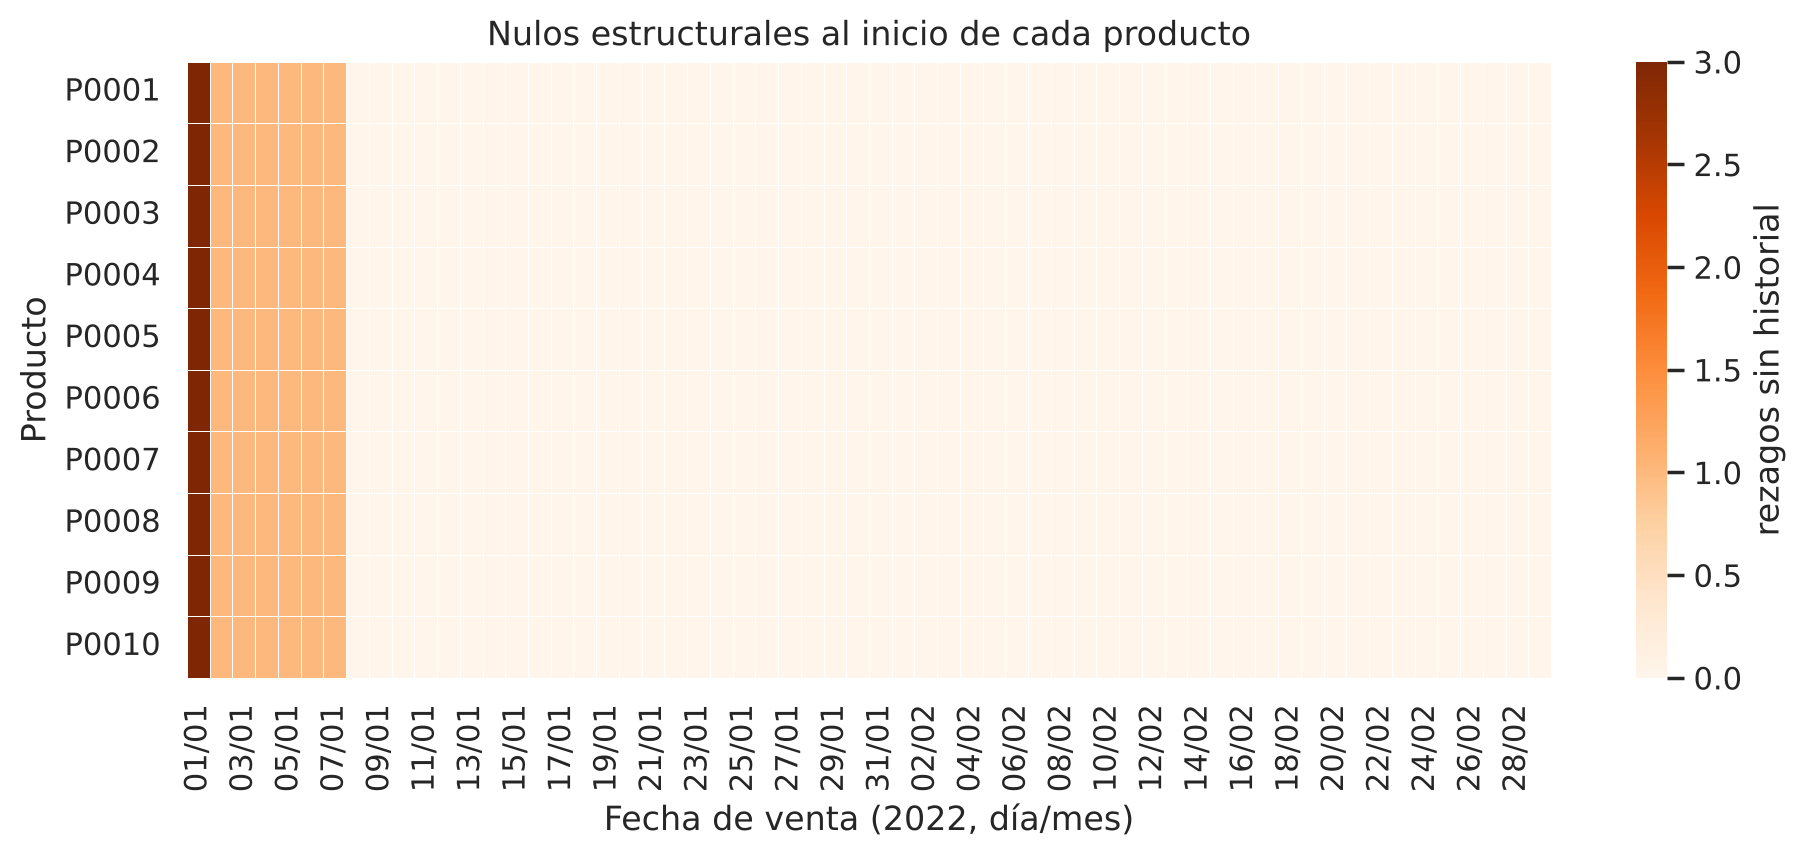

In [3]:
REZAGOS = ["ventas_dia_anterior", "ventas_hace_7_dias", "promedio_movil_7d"]
indice_dia = (df_crudo["fecha_venta"] - df_crudo["fecha_venta"].min()).dt.days  # 0 = primer día

historial_original = pd.read_csv(RUTA_DATOS.with_name("sales_history.csv"))
assert historial_original.isna().sum().sum() == 0                      # el dato original no tiene nulos
assert df_crudo[REZAGOS].isna().sum().sum() == 90                      # 90 celdas de calentamiento
assert df_crudo[REZAGOS].isna().any(axis=1).sum() == 70                # concentradas en 70 filas
assert df_crudo["ventas_hace_7_dias"].isna().eq(indice_dia < 7).all()  # primeros 7 días de cada producto
assert df_crudo[["ventas_dia_anterior", "promedio_movil_7d"]].isna().all(axis=1).eq(indice_dia == 0).all()

mapa = df_crudo.assign(rezagos_nulos=df_crudo[REZAGOS].isna().sum(axis=1)).pivot(
    index="product_id", columns="fecha_venta", values="rezagos_nulos")
mapa.columns = mapa.columns.strftime("%d/%m")
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(mapa, cmap="Oranges", linewidths=0.3, linecolor="white", cbar_kws={"label": "rezagos sin historial"}, ax=ax)
ax.set(title="Nulos estructurales al inicio de cada producto", xlabel="Fecha de venta (2022, día/mes)", ylabel="Producto")
guardar(fig, "eda_nulos.png")
plt.show()

La decisión es eliminar esas filas (`dropna`, sección 3.2) y no imputarlas: rellenar un rezago con la media o con ceros inventaría ventas que no ocurrieron.

### 2.3 Distribución del target

¿Cómo se distribuyen las ventas y cuánto cambian según el día de la semana?

,count,mean,std,min,25%,50%,75%,max,asimetria
cantidad_vendida,600.0,151.2,57.8,67.0,110.0,140.5,172.0,411.0,1.43


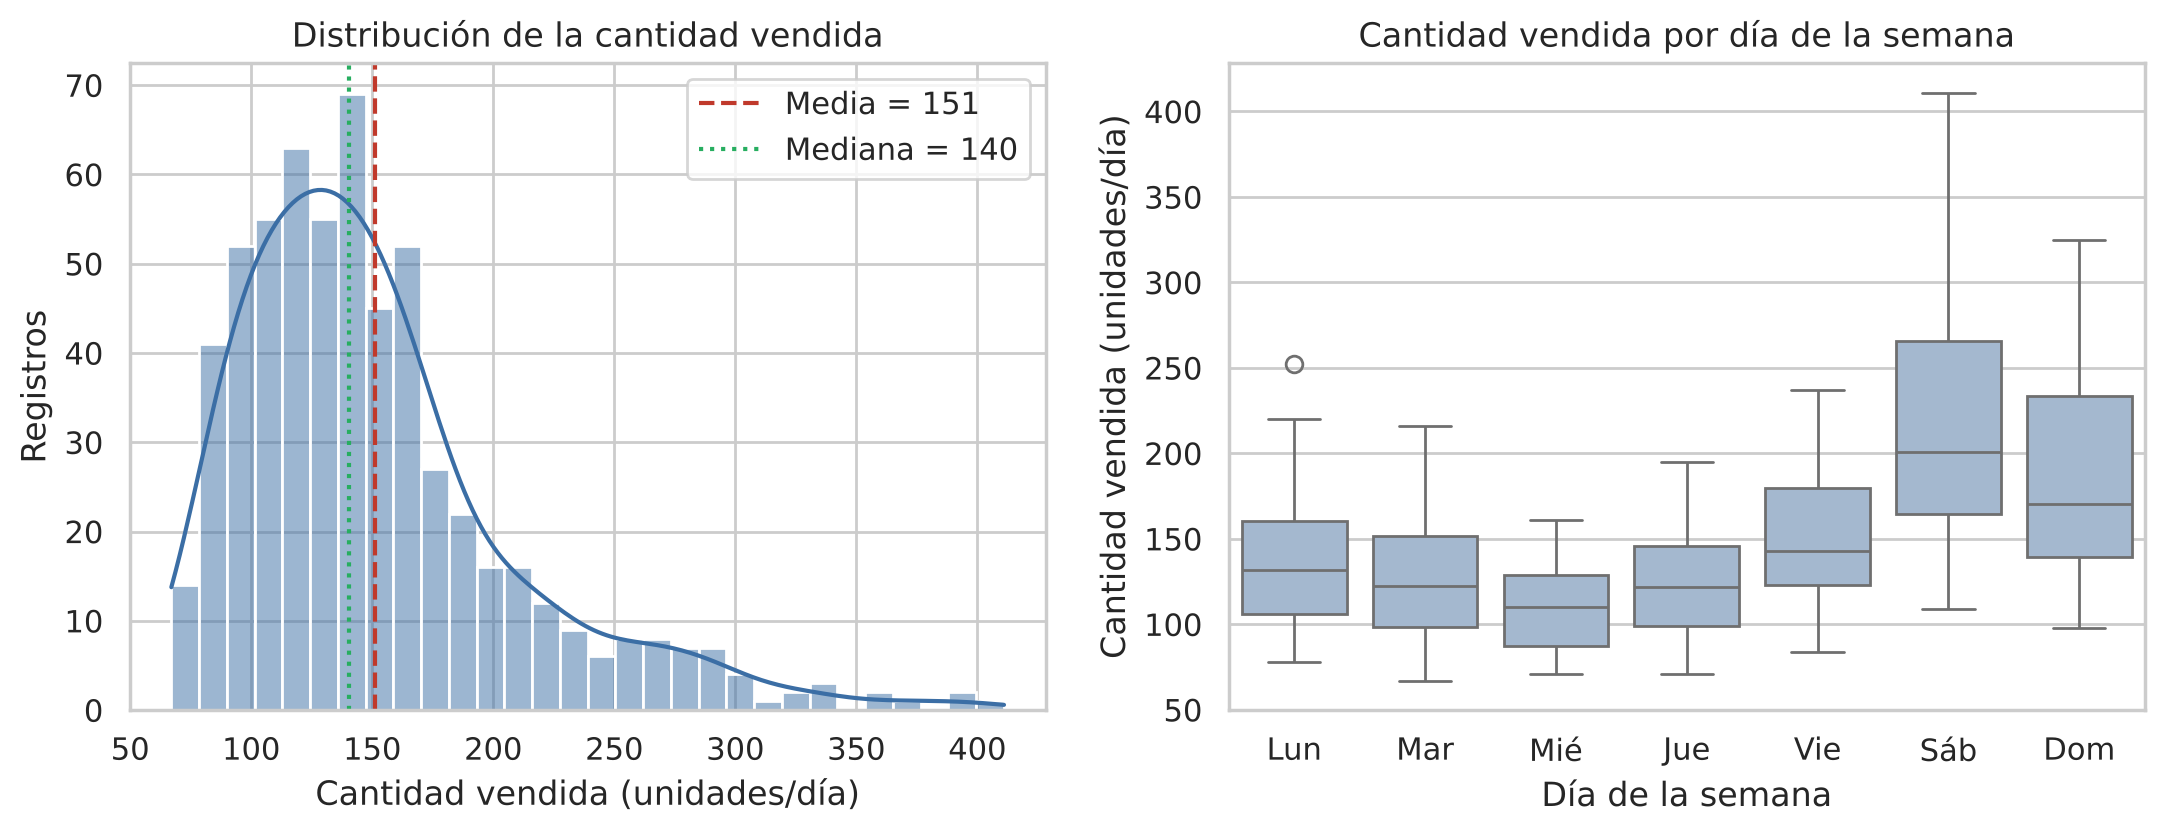

In [4]:
objetivo = df["cantidad_vendida"]
display(objetivo.describe().round(1).to_frame().T.assign(asimetria=round(objetivo.skew(), 2)))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(objetivo, bins=30, kde=True, color="#3b6ea5", ax=ejes[0])
ejes[0].axvline(objetivo.mean(), color="#c0392b", ls="--", label=f"Media = {objetivo.mean():.0f}")
ejes[0].axvline(objetivo.median(), color="#27ae60", ls=":", label=f"Mediana = {objetivo.median():.0f}")
ejes[0].set(title="Distribución de la cantidad vendida", xlabel="Cantidad vendida (unidades/día)", ylabel="Registros")
ejes[0].legend()
sns.boxplot(data=df, x="dia_semana", y="cantidad_vendida", color="#9db8d6", ax=ejes[1])
ejes[1].set_xticks(range(7), ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"])
ejes[1].set(title="Cantidad vendida por día de la semana", xlabel="Día de la semana", ylabel="Cantidad vendida (unidades/día)")
guardar(fig, "eda_distribucion.png")
plt.show()

Interpretación: la distribución tiene cola derecha (la media supera a la mediana) y el sábado y el domingo venden claramente más que entre semana. Por eso esperamos que `dia_semana` y `es_fin_de_semana` aporten, y por eso el target se escala dentro del pipeline (R2).

### 2.4 Ventas por categoría y producto

¿Cuánto cambia el nivel de ventas entre categorías y productos?

,productos,filas,media,desviacion
categoria,,,,
Bebidas,1,60,212.2,68.1
Snacks,1,60,199.5,67.6
Alimentos,5,300,150.0,48.7
Cuidado personal,1,60,123.6,27.5
Hogar,1,60,116.9,30.6
Limpieza,1,60,109.9,33.7


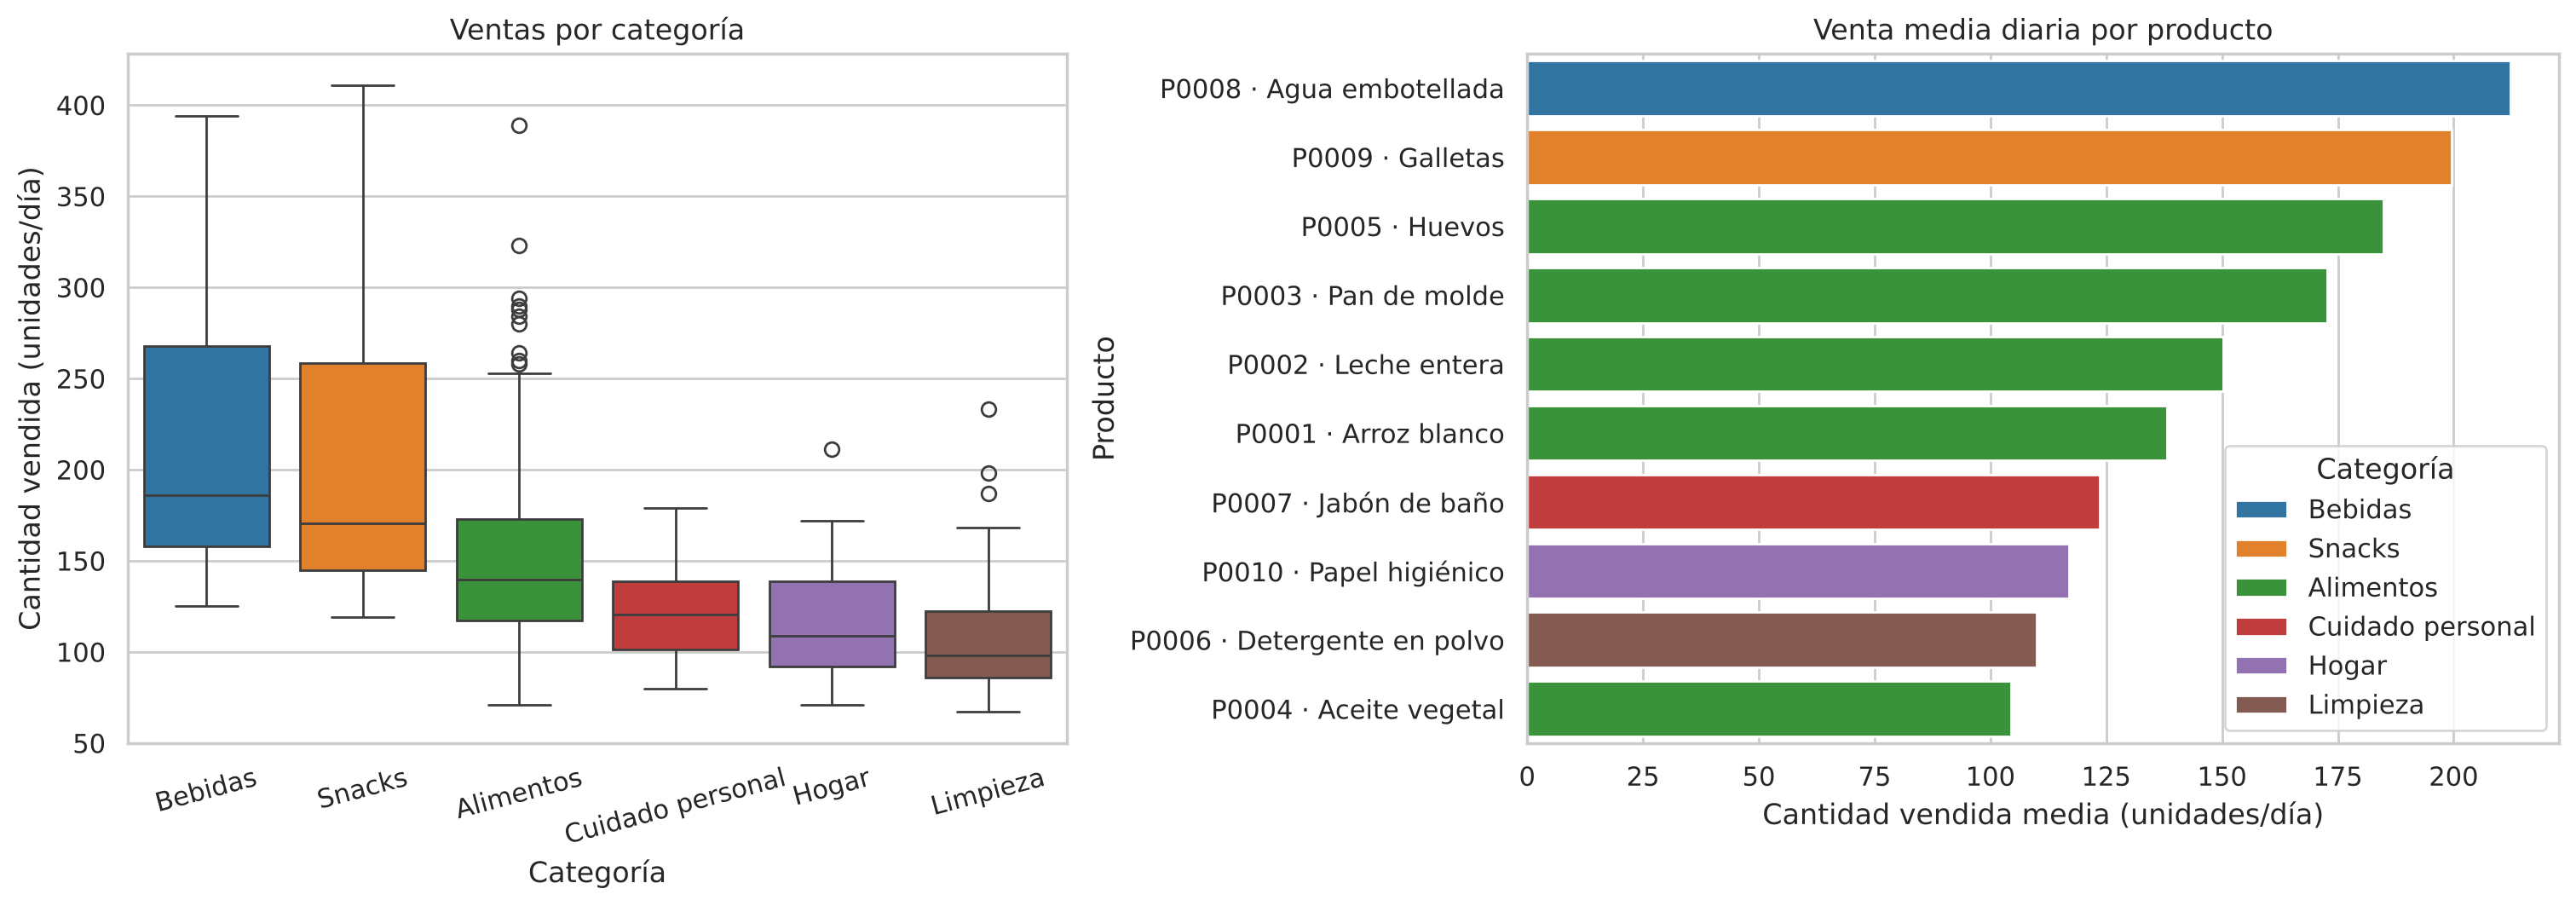

In [5]:
por_categoria = (
    df.groupby("categoria")
    .agg(productos=("product_id", "nunique"), filas=("cantidad_vendida", "size"),
         media=("cantidad_vendida", "mean"), desviacion=("cantidad_vendida", "std"))
    .round(1).sort_values("media", ascending=False)
)
display(por_categoria)
ORDEN_CATEGORIAS = por_categoria.index.tolist()
PALETA = dict(zip(ORDEN_CATEGORIAS, sns.color_palette("tab10", len(ORDEN_CATEGORIAS))))

por_producto = df.groupby(["product_id", "nombre", "categoria"], as_index=False)["cantidad_vendida"].mean()
por_producto["producto"] = por_producto["product_id"] + " · " + por_producto["nombre"]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.1]}, layout="constrained")
sns.boxplot(data=df, x="categoria", y="cantidad_vendida", order=ORDEN_CATEGORIAS, hue="categoria", palette=PALETA, legend=False, ax=ejes[0])
ejes[0].set(title="Ventas por categoría", xlabel="Categoría", ylabel="Cantidad vendida (unidades/día)")
ejes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=por_producto.sort_values("cantidad_vendida", ascending=False), x="cantidad_vendida", y="producto",
            hue="categoria", palette=PALETA, dodge=False, ax=ejes[1])
ejes[1].set(title="Venta media diaria por producto", xlabel="Cantidad vendida media (unidades/día)", ylabel="Producto")
ejes[1].legend(title="Categoría", loc="lower right")
guardar(fig, "eda_categoria.png")
plt.show()

Interpretación: Agua embotellada (Bebidas) y Galletas (Snacks) venden casi el doble que Detergente en polvo y Aceite vegetal, y su dispersión es mayor que la de Cuidado personal. Cinco de las seis categorías tienen un solo producto y Alimentos tiene cinco, así que `categoria` repite casi por completo a `product_id` (ver 3.6).

### 2.5 Evolución temporal

¿Hay tendencia, estacionalidad semanal o efecto de feriados?

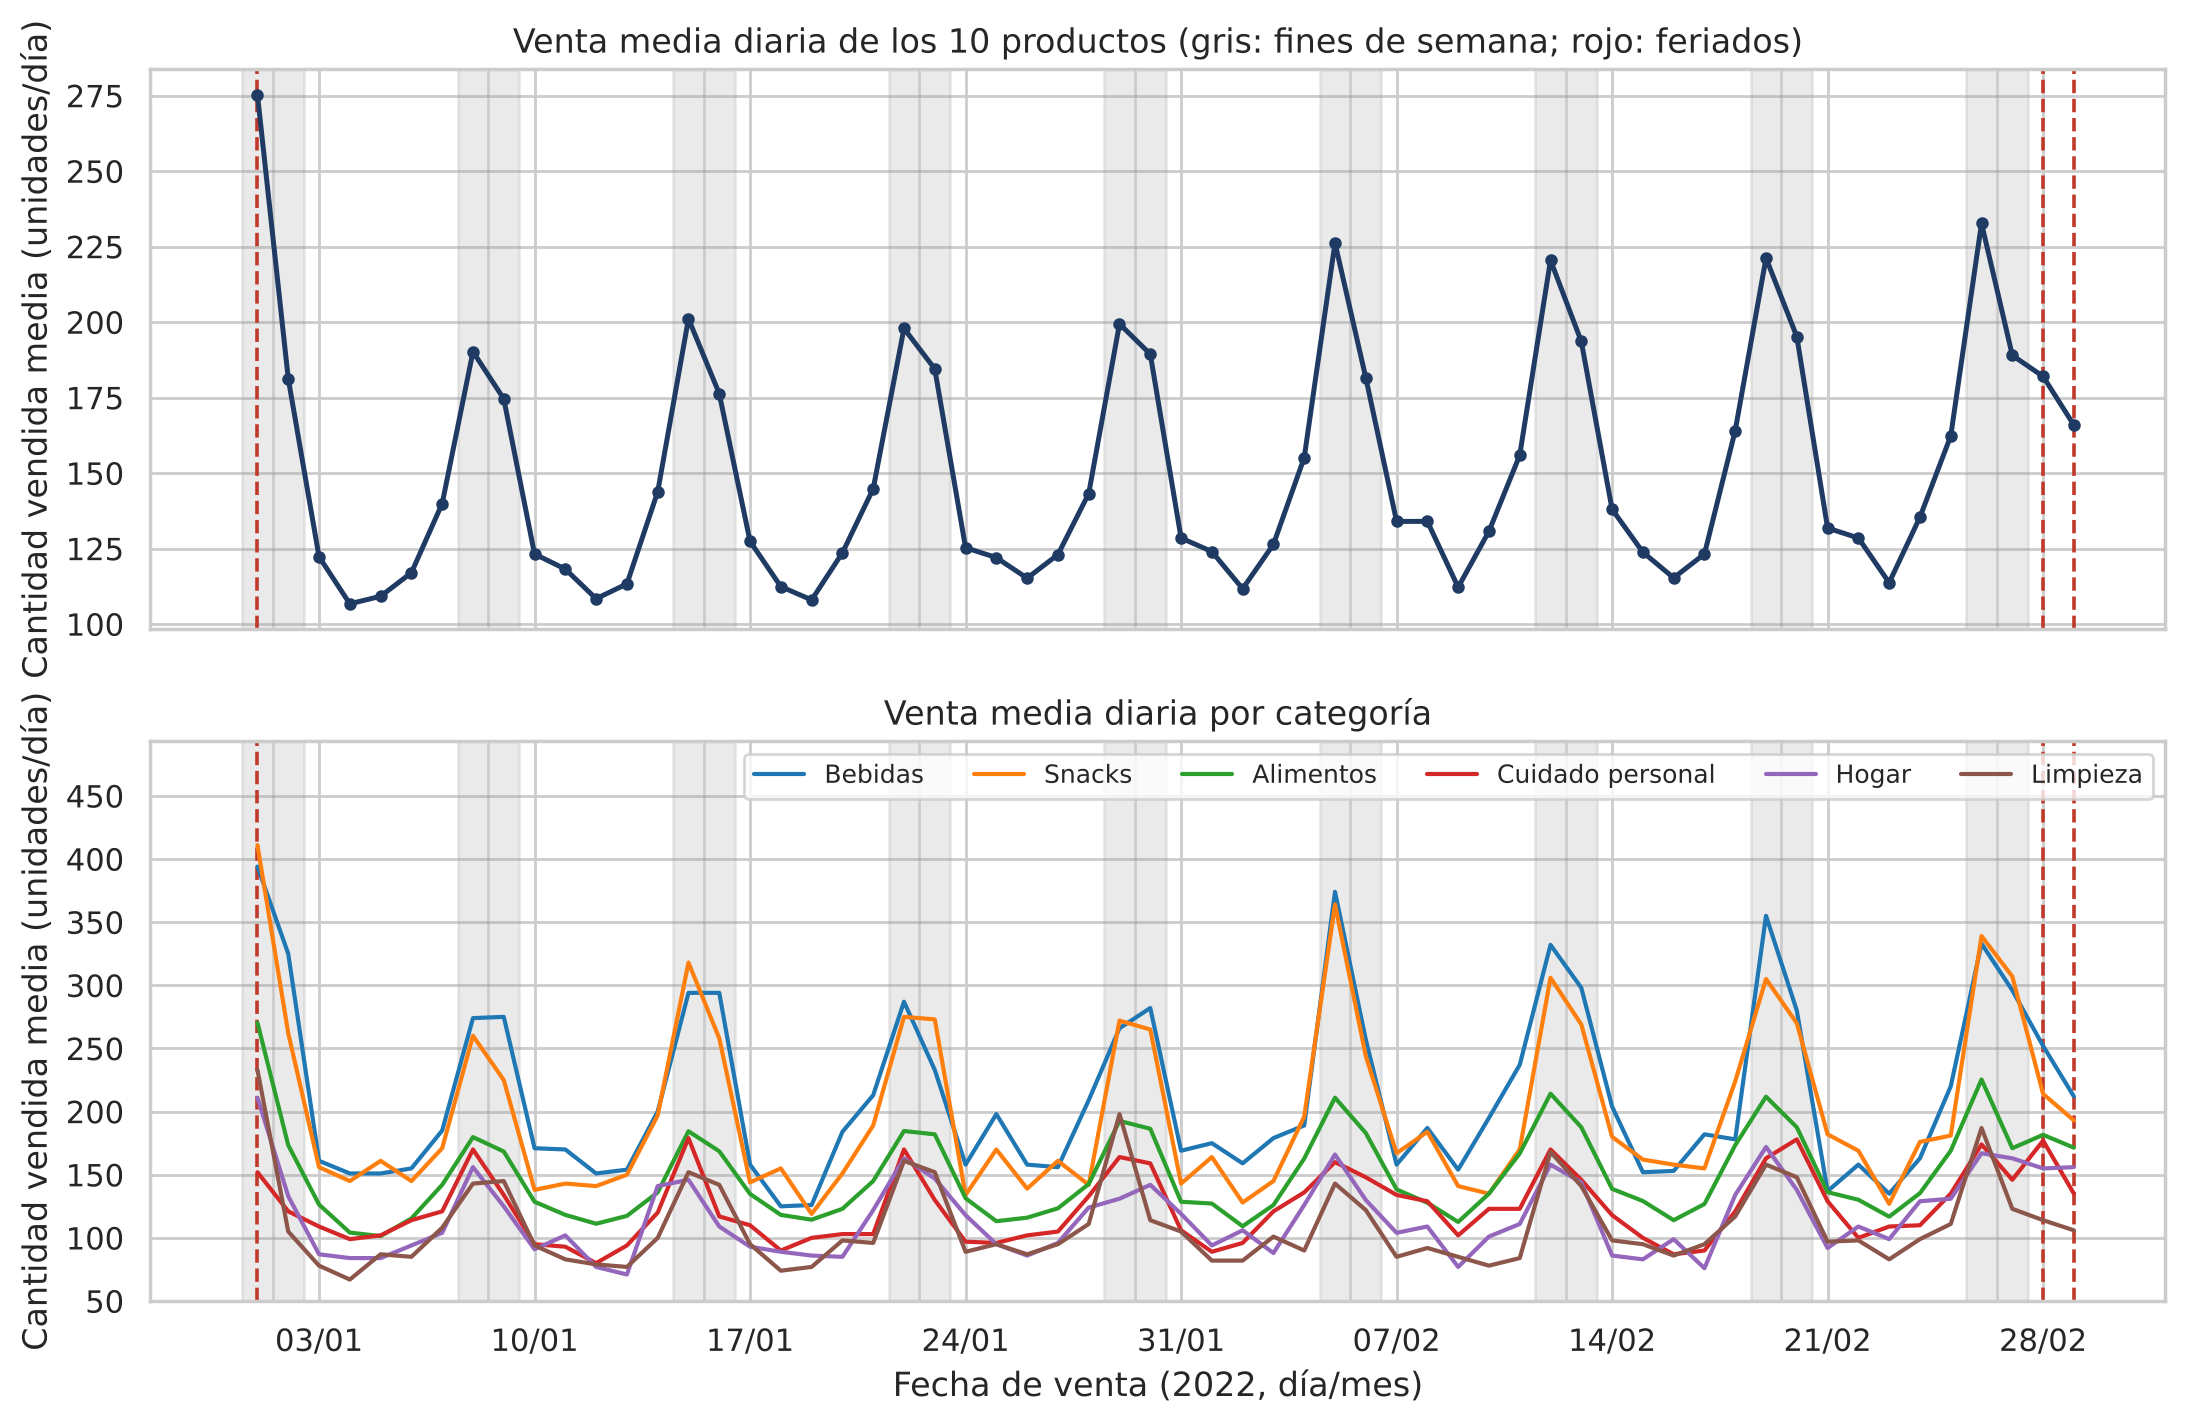

In [6]:
diario = df.groupby("fecha_venta")["cantidad_vendida"].mean()
por_categoria_dia = df.pivot_table(index="fecha_venta", columns="categoria", values="cantidad_vendida")
fines_de_semana = diario.index[diario.index.dayofweek >= 5]
feriados = df.loc[df["es_feriado"] == 1, "fecha_venta"].unique()

fig, ejes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax in ejes:
    for dia in fines_de_semana:
        ax.axvspan(dia - pd.Timedelta(hours=12), dia + pd.Timedelta(hours=12), color="#999999", alpha=0.2)
    for dia in feriados:
        ax.axvline(dia, color="#c0392b", ls="--", lw=1.3)
ejes[0].plot(diario, marker="o", ms=3.5, lw=1.8, color="#1f3b63")
ejes[0].set(title="Venta media diaria de los 10 productos (gris: fines de semana; rojo: feriados)", ylabel="Cantidad vendida media (unidades/día)")
for categoria in ORDEN_CATEGORIAS:
    ejes[1].plot(por_categoria_dia[categoria], lw=1.5, color=PALETA[categoria], label=categoria)
ejes[1].set(title="Venta media diaria por categoría", xlabel="Fecha de venta (2022, día/mes)", ylabel="Cantidad vendida media (unidades/día)",
            ylim=(None, por_categoria_dia.max().max() * 1.2))
ejes[1].legend(ncol=6, fontsize=9, loc="upper right")
ejes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
ejes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
guardar(fig, "eda_temporal.png")
plt.show()

Interpretación: la estacionalidad semanal es clara (pico el sábado, mínimo a mitad de semana) y no hay una tendencia marcada, salvo un leve aumento de los picos en febrero. Los feriados caen justo al inicio y al final del periodo, lo que complica el split (ver 3.6). `ventas_hace_7_dias` captura justamente ese patrón semanal.

## 3. Features y split

Regla del plan: ninguna variable puede contener información del futuro ni del target. R2, R3 y R4 reciben `X_train`, `X_test`, `y_train`, `y_test` y `COLUMNAS` sin modificarlos.

### 3.1 Variables

Cada columna entra como predictora numérica o categórica, es el target o se excluye por estos motivos:

| Columnas excluidas | Motivo |
|---|---|
| `anio`, `stock_actual`, `unidad` | `anio` es constante; `stock_actual` y `unidad` son fijas por producto y solo lo identifican |
| `nombre`, `nombre_dia`, `tipo_dia` | Texto redundante con `product_id`, `dia_semana` y `es_fin_de_semana`/`es_feriado` |
| `fecha_venta`, `semana_iso` | La fecha solo ordena y divide; `semana_iso` no es monótona (el 1-ene-2022 es la semana 52) y el plan no la lista |

In [7]:
NUM = ["mes", "dia_del_mes", "dia_semana", "es_fin_de_semana", "es_feriado", "semana_del_periodo",
       "ventas_dia_anterior", "ventas_hace_7_dias", "promedio_movil_7d", "stock_en_momento", "dias_para_expirar"]
CAT = ["categoria", "product_id"]  # categoria = f(product_id): se mantienen ambas (plan), ver 3.6
TARGET = "cantidad_vendida"
EXCLUIDAS = {
    "stock_actual": "constante por producto", "nombre": "1 a 1 con product_id", "unidad": "fija por producto",
    "fecha_venta": "solo ordena y divide", "anio": "constante", "nombre_dia": "1 a 1 con dia_semana",
    "tipo_dia": "derivada de es_fin_de_semana y es_feriado", "semana_iso": "no es monótona (1-ene = semana 52)",
}

assert set(NUM) | set(CAT) | set(EXCLUIDAS) | {TARGET} == set(df_crudo.columns)
assert df_crudo["anio"].nunique() == 1
assert df_crudo.groupby("product_id")[["stock_actual", "nombre", "unidad"]].nunique().max().max() == 1
assert df_crudo.groupby("dia_semana")["nombre_dia"].nunique().max() == 1

roles = {**dict.fromkeys(NUM, "numérica"), **dict.fromkeys(CAT, "categórica"), TARGET: "target", **dict.fromkeys(EXCLUIDAS, "excluida")}
tabla_variables = pd.DataFrame({"rol": roles, "motivo_exclusion": pd.Series(EXCLUIDAS)}).rename_axis("variable")
tabla_variables.to_csv("resultados/tabla_variables.csv")

### 3.2 Eliminación de filas con nulos

Aplicamos `dropna` sobre las predictoras numéricas y el target. Desde aquí `df` es el dataset limpio (el del modelado) y `df_crudo` conserva las filas originales, así que la celda se puede ejecutar de nuevo sin romper la auditoría de 3.5.

In [8]:
df = df_crudo.dropna(subset=NUM + [TARGET]).reset_index(drop=True)

assert len(df) == 530 and df[NUM + [TARGET]].notna().all().all()
assert (df.groupby("product_id").size() == 53).all()

pd.DataFrame(
    {"filas": [len(df_crudo), len(df)], "primer día": [d["fecha_venta"].min().date() for d in (df_crudo, df)],
     "último día": [d["fecha_venta"].max().date() for d in (df_crudo, df)]},
    index=["antes (EDA)", "después (modelado)"],
)

,filas,primer día,último día
antes (EDA),600,2022-01-01,2022-03-01
después (modelado),530,2022-01-08,2022-03-01


### 3.3 Matriz X y vector y

El SVR solo trabaja con números, así que `categoria` y `product_id` pasan a columnas 0/1 (one-hot). Con `drop_first=True` se evita la categoría de referencia redundante. Verificamos que `X` no tenga nulos ni columnas constantes y que el target no esté entre las predictoras.

In [9]:
X = pd.get_dummies(df[NUM + CAT], columns=CAT, drop_first=True, dtype=float)
y = df[TARGET]

assert X.shape == (530, 25) and X.isna().sum().sum() == 0 and y.isna().sum() == 0
assert (X.nunique() > 1).all() and TARGET not in X.columns
assert X.select_dtypes("number").shape[1] == X.shape[1]

pd.Series({"filas": X.shape[0], "columnas": X.shape[1], "dummies de categoria": X.filter(like="categoria_").shape[1],
           "dummies de product_id": X.filter(like="product_id_").shape[1]}, name="X")

filas                    530
columnas                  25
dummies de categoria       5
dummies de product_id      9
Name: X, dtype: int64

### 3.4 Split temporal 80/20 y lista COLUMNAS

El split es por fecha, no aleatorio: uno aleatorio dejaría en train días vecinos de los de test y las métricas saldrían infladas. El corte es el cuantil 0,8 de `fecha_venta` y se hace por días completos, así que los 10 productos entran juntos. `COLUMNAS` guarda el orden de columnas que R3 necesita en `predecir_venta()`.

In [10]:
corte = df["fecha_venta"].quantile(0.8)
es_train = df["fecha_venta"] <= corte
X_train, y_train = X[es_train], y[es_train]
X_test, y_test = X[~es_train], y[~es_train]
COLUMNAS = X_train.columns.tolist()

assert df.loc[es_train, "fecha_venta"].max() < df.loc[~es_train, "fecha_venta"].min()  # sin solapamiento
assert set(df.loc[es_train, "product_id"]) == set(df.loc[~es_train, "product_id"])     # los 10 productos en ambos
assert abs(es_train.mean() - 0.8) < 0.02                                               # proporción cercana a 80/20
assert COLUMNAS == X_test.columns.tolist() and not X_train.isna().any().any() and not X_test.isna().any().any()

(df.assign(conjunto=np.where(es_train, "train", "test")).groupby("conjunto")
   .agg(filas=("fecha_venta", "size"), primer_dia=("fecha_venta", "min"), ultimo_dia=("fecha_venta", "max"),
        dias=("fecha_venta", "nunique"), productos=("product_id", "nunique"))
   .assign(porcentaje=lambda t: (t["filas"] / len(df) * 100).round(1)).loc[["train", "test"]])

,filas,primer_dia,ultimo_dia,dias,productos,porcentaje
conjunto,,,,,,
train,430,2022-01-08,2022-02-19,43,10,81.1
test,100,2022-02-20,2022-03-01,10,10,18.9


### 3.5 Revisión de fuga de información

Comprobamos con cálculos que ninguna predictora usa información del futuro ni del target. Cada control da verdadero o falso y la celda falla si alguno no se cumple.

In [11]:
ordenado = df_crudo.sort_values(["product_id", "fecha_venta"])
ventas = ordenado.groupby("product_id")["cantidad_vendida"]
media_previa = ventas.transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean())
media_con_hoy = ventas.transform(lambda s: s.rolling(7, min_periods=1).mean())
stock_esperado = ordenado.groupby("product_id")["stock_en_momento"].shift(1) - ventas.shift(1)
correlacion = df[NUM].corrwith(df[TARGET]).abs().sort_values(ascending=False)


def coincide(columna, esperado):
    """True si la columna vale lo esperado y los nulos están en las mismas filas."""
    presente = ordenado[columna].notna()
    return bool(np.array_equal(presente, esperado.notna()) and np.allclose(ordenado.loc[presente, columna], esperado[presente]))


controles = {
    "ventas_dia_anterior = venta del día previo": coincide("ventas_dia_anterior", ventas.shift(1)),
    "ventas_hace_7_dias = venta de 7 días antes": coincide("ventas_hace_7_dias", ventas.shift(7)),
    "promedio_movil_7d usa solo días previos": coincide("promedio_movil_7d", media_previa),
    "promedio_movil_7d no incluye el día actual": not coincide("promedio_movil_7d", media_con_hoy),
    "stock_en_momento no descuenta las ventas del propio día": bool(((ordenado["stock_en_momento"] - stock_esperado).dropna() >= 0).all()),
    "stock_actual es constante por producto (excluida)": bool((ordenado.groupby("product_id")["stock_actual"].nunique() == 1).all()),
    "el target no está en X": TARGET not in X.columns,
    f"ninguna predictora con |r| ≥ 0,95 (máxima: {correlacion.index[0]}, {correlacion.iloc[0]:.2f})": bool(correlacion.max() < 0.95),
    "las fechas de train son anteriores a las de test": bool(df.loc[es_train, "fecha_venta"].max() < df.loc[~es_train, "fecha_venta"].min()),
}
assert all(controles.values()), "Hay un control de fuga que no se cumple"
pd.Series(controles, name="cumple").map({True: "✔", False: "✘"}).to_frame()

,cumple
ventas_dia_anterior = venta del día previo,✔
ventas_hace_7_dias = venta de 7 días antes,✔
promedio_movil_7d usa solo días previos,✔
promedio_movil_7d no incluye el día actual,✔
stock_en_momento no descuenta las ventas del propio día,✔
stock_actual es constante por producto (excluida),✔
el target no está en X,✔
"ninguna predictora con |r| ≥ 0,95 (máxima: ventas_hace_7_dias, 0.89)",✔
las fechas de train son anteriores a las de test,✔


Resultado: los rezagos usan solo días previos y `stock_en_momento` es el inventario al inicio del día, así que ninguna variable usa información del futuro.

### 3.6 Diagnóstico para R2 y R4

Con un split temporal, algunas variables salen del rango de train. La tabla muestra qué porcentaje de test queda fuera de ese rango y buscamos columnas duplicadas en `X`.

In [12]:
riesgo = ["es_feriado", "mes", "semana_del_periodo", "dias_para_expirar", "stock_en_momento", "dia_del_mes"]
rangos = X_train[riesgo].agg(["min", "max"]).T.join(X_test[riesgo].agg(["min", "max"]).T, lsuffix="_train", rsuffix="_test")
fuera_de_rango = (X_test[riesgo] < X_train[riesgo].min()) | (X_test[riesgo] > X_train[riesgo].max())
rangos["porcentaje_test_fuera"] = (fuera_de_rango.mean() * 100).round(1)
display(rangos)

X.columns[X.T.duplicated()].tolist()  # columnas idénticas a otra anterior

,min_train,max_train,min_test,max_test,porcentaje_test_fuera
es_feriado,0,0,0,1,20.0
mes,1,2,2,3,10.0
semana_del_periodo,2,8,8,9,40.0
dias_para_expirar,82,383,72,340,10.0
stock_en_momento,259,799,290,799,0.0
dia_del_mes,1,31,1,28,0.0


['product_id_P0006',
 'product_id_P0007',
 'product_id_P0008',
 'product_id_P0009',
 'product_id_P0010']

Hallazgos para el equipo (no cambian las decisiones cerradas del plan):

- `es_feriado` vale 0 en train: los dos feriados de test (28-feb y 1-mar) no se pueden aprender, y el caso de demanda alta de `predecir_venta()` no puede apoyarse en esa variable.
- `mes`, `semana_del_periodo` y `dias_para_expirar` salen del rango de train (tabla anterior): riesgo de extrapolación.
- Las 5 dummies de `categoria` duplican a las de `product_id` (lista anterior). Se mantienen ambas, como define el plan; es una decisión de equipo.
- Test tiene 100 filas y 10 días: las métricas serán ruidosas, conviene reportar también el RMSE de validación cruzada.
- En test los rezagos usan ventas reales del día anterior: es un pronóstico a 1 día, no a varios (importante al comparar con el LSTM de la práctica 001).